Primer valor crítico: 1.2373
Segundo valor crítico: 14.4494
Varianza muestral: 0.8034
Valor muestral del estadístico: 4.8207
valor1: 0.4330
valor2: 0.5670
p-valor: 0.8660


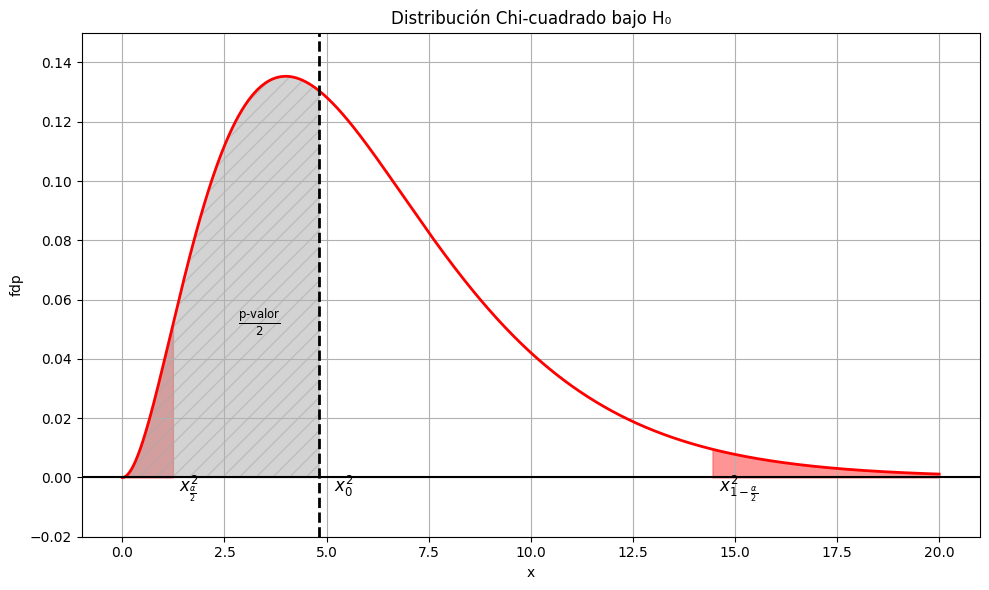

In [1]:
# Ejemplo de test de chi-cuadrado para varianza

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
import statsmodels.api as sm

# --- Conversión de mpg a litros/100km ---
cte = 1.60934 / 3.78541  # km/l

# Cargar dataset mtcars
mtcars = sm.datasets.get_rdataset("mtcars", "datasets").data.copy()
mtcars['mpg'] = 100 / (mtcars['mpg'] * cte)  # Conversión

# Filtrar autos con 6 cilindros
datospre = mtcars[mtcars['cyl'] == 6]
datos = datospre['mpg'].values

# --- Parámetros del test ---
alpha = 0.05
var_muestral = np.var(datos, ddof=1)
df = len(datos) - 1
crit1 = chi2.ppf(alpha / 2, df)
crit2 = chi2.ppf(1 - alpha / 2, df)

print(f'Primer valor crítico: {crit1:.4f}')
print(f'Segundo valor crítico: {crit2:.4f}')
print(f'Varianza muestral: {var_muestral:.4f}')

# Hipótesis nula: sigma² = 1.0
sigma2 = 1.0
chi20 = df * var_muestral / sigma2
print(f'Valor muestral del estadístico: {chi20:.4f}')

pvalor1 = chi2.cdf(chi20, df)
pvalor2 = chi2.sf(chi20, df)
p_valor = 2 * min(pvalor1, pvalor2)
print(f'valor1: {pvalor1:.4f}')
print(f'valor2: {pvalor2:.4f}')
print(f'p-valor: {p_valor:.4f}')

# --- Gráfico de la distribución chi-cuadrado ---
xLims = (0, 20)
x = np.linspace(*xLims, 1000)
y = chi2.pdf(x, df)

# Regiones de rechazo
right = np.linspace(crit2, xLims[1], 100)
left = np.linspace(xLims[0], crit1, 100)
yH0r = chi2.pdf(right, df)
yH0l = chi2.pdf(left, df)

# Región del estadístico observado
left2 = np.linspace(xLims[0], chi20, 100)
yH0l2 = chi2.pdf(left2, df)

# --- Visualización ---
plt.figure(figsize=(10, 6))
plt.plot(x, y, color='red', linewidth=2, label='Chi-cuadrado H₀')
plt.fill_between(right, yH0r, color=(1, 0.3, 0.3, 0.6))
plt.fill_between(left, yH0l, color=(1, 0.3, 0.3, 0.6))
plt.fill_between(left2, yH0l2, color='darkgray', alpha=0.5, hatch='//')

plt.axvline(chi20, color='black', linestyle='--', linewidth=2)
plt.axhline(0, color='black')

# Etiquetas
plt.text(chi20 + 0.35, -0.005, r'$x_0^2$', fontsize=12)
plt.text(chi20 - 2, 0.05, r'$\frac{\mathrm{p\text{-}valor}}{2}$', fontsize=12)
plt.text(crit1 + 0.15, -0.005, r'$x_{\frac{\alpha}{2}}^2$', fontsize=12)
plt.text(crit2 + 0.15, -0.005, r'$x_{1-\frac{\alpha}{2}}^2$', fontsize=12)

# Estética
plt.title("Distribución Chi-cuadrado bajo H₀")
plt.xlabel("x")
plt.ylabel("fdp")
plt.ylim(-0.02, 0.15)
plt.grid(True)
plt.tight_layout()
plt.show()
